# Prelude

In [1]:
%cd /home/mfixman/TP/MyPyCop

/home/mfixman/Dropbox/continuous/TP/MyPyCop


In [2]:
import pandas
import scipy
import numpy
import matplotlib
import seaborn
import json
import glob

from matplotlib import pyplot

from pandas import Series, DataFrame

In [3]:
seaborn.set()

# Getting Data

In [4]:
data = pandas.concat(
    [
        pandas.read_csv(
            'results/SATReset_Tuesday.csv',
        ),
        pandas.read_csv(
            'results/SATResetFinalControl.csv',
        )
    ],
    ignore_index = True,
).drop_duplicates(['problem', 'strategy'], keep = 'last')
data['problem_type'] = numpy.select([data.problem_spc_tags.str.contains('FOF'), data.problem_spc_tags.str.contains('CNF')], ['FOF', 'CNF'], default = None)

good_problems = data.groupby('problem').strategy.nunique().loc[lambda x: x == x.max()].index
data = data[data.problem.isin(good_problems)]

valid_strategies = {
    'FirstAction': 'FirstAction',
    'LeanCopCut': 'LeanCoP',
    'SATSolve': 'SATCoP',
    'SATSolveLiteral': 'SATCoP_2',
    'SATResetAtStaleBacktrack': 'SATResetCoP',
}

data = data[data.strategy.isin(valid_strategies.keys())].replace({'strategy': valid_strategies})
data = data.sort_values(by = 'strategy', key = lambda x: x.replace({k: v for (v, k) in enumerate(valid_strategies.values())}))

assert data.groupby('problem').strategy.count().nunique() == 1
assert data.groupby('strategy').problem.count().nunique() == 1
assert not data.problem_type.isnull().any()
assert data.strategy.nunique() == len(valid_strategies)

/tmp/ipykernel_1240573/3561472614.py:26: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data = data.sort_values(by = 'strategy', key = lambda x: x.replace({k: v for (v, k) in enumerate(valid_strategies.values())}))


In [5]:
data.strategy.value_counts()

strategy
FirstAction    16442
LeanCoP        16442
SATCoP         16442
SATCoP_2       16442
SATResetCoP    16442
Name: count, dtype: int64

In [6]:
{k: v for (v, k) in enumerate(valid_strategies.keys())}

{'FirstAction': 0,
 'LeanCopCut': 1,
 'SATSolve': 2,
 'SATSolveLiteral': 3,
 'SATResetAtStaleBacktrack': 4}

In [7]:
data.head()

,problem,strategy,status,result,solved,steps,time_ms,problem_spc_tags,problem_typed,problem_declared_status,problem_declared_status_kind,info,error,problem_type
82844,GRP332-1.p,FirstAction,timeout,NaN,False,105053.0,90001.0,CNF_UNS_RFO_PEQ_NUE,False,Unsatisfiable,unsat,NaN,NaN,CNF
82816,GRP297-1.p,FirstAction,timeout,NaN,False,110591.0,90001.0,CNF_UNS_RFO_PEQ_NUE,False,Unsatisfiable,unsat,NaN,NaN,CNF
82820,GRP302-1.p,FirstAction,timeout,NaN,False,100187.0,90000.0,CNF_UNS_RFO_PEQ_NUE,False,Unsatisfiable,unsat,NaN,NaN,CNF
82824,GRP307-1.p,FirstAction,timeout,NaN,False,105153.0,90001.0,CNF_UNS_RFO_PEQ_NUE,False,Unsatisfiable,unsat,NaN,NaN,CNF
82828,GRP312-1.p,FirstAction,timeout,NaN,False,45745.0,90000.0,CNF_UNS_RFO_PEQ_NUE,False,Unsatisfiable,unsat,NaN,NaN,CNF


In [8]:
data.groupby('strategy').problem.nunique().sort_values()

strategy
FirstAction    16442
LeanCoP        16442
SATCoP         16442
SATCoP_2       16442
SATResetCoP    16442
Name: problem, dtype: int64

In [9]:
data.groupby('strategy').steps.max()

strategy
FirstAction    1000000.0
LeanCoP        1000000.0
SATCoP         1000000.0
SATCoP_2       1000000.0
SATResetCoP    1000000.0
Name: steps, dtype: float64

In [10]:
problems = data.problem.str[:3].value_counts().sort_index()
pandas.concat(
    [
        problems[0::3].reset_index(),
        problems[1::3].reset_index(),
        problems[2::3].reset_index(),
    ],
    axis = 1,
).fillna('')

,problem,count,problem,count,problem,count
0,AGT,270,ALG,2315,ANA,480.0
1,BIO,30,BOO,750,CAT,670.0
2,COL,1260,COM,375,CSR,4770.0
3,FLD,1405,GEG,5,GEO,4480.0
4,GRA,170,GRP,5330,HAL,50.0
5,HEN,340,HWC,30,HWV,1475.0
6,ITP,500,KLE,1270,KRS,1490.0
7,LAT,3030,LCL,4610,LDA,250.0
8,MED,60,MGT,790,MSC,125.0
9,MVA,75,NLP,2810,NUM,5315.0


# Analysing

In [11]:
control = ['FirstAction', 'LeanCopCut']

In [12]:
data.groupby('strategy').problem.count()

strategy
FirstAction    16442
LeanCoP        16442
SATCoP         16442
SATCoP_2       16442
SATResetCoP    16442
Name: problem, dtype: int64

In [13]:
pandas.crosstab(
    data.strategy,
    data.result,
    margins = True,
).sort_values('All')

result,Non-Theorem: no positive start clauses,Theorem,Theorem (SAT),All
strategy,,,,
FirstAction,46,792,0,838
SATCoP,2,0,1829,1831
LeanCoP,2,1856,0,1858
SATCoP_2,2,0,2423,2425
SATResetCoP,2,0,2861,2863
All,54,2648,7113,9815


In [14]:
data[data.problem == 'PUZ053-1.p']

,problem,strategy,status,result,solved,steps,time_ms,problem_spc_tags,problem_typed,problem_declared_status,problem_declared_status_kind,info,error,problem_type
103204,PUZ053-1.p,FirstAction,timeout,NaN,False,2478.0,90070.0,CNF_SAT_EPR_NEQ,False,Satisfiable,sat,NaN,NaN,CNF
103205,PUZ053-1.p,LeanCoP,timeout,NaN,False,14452.0,90001.0,CNF_SAT_EPR_NEQ,False,Satisfiable,sat,NaN,NaN,CNF
103206,PUZ053-1.p,SATCoP,timeout,NaN,False,8197.0,90006.0,CNF_SAT_EPR_NEQ,False,Satisfiable,sat,NaN,NaN,CNF
103207,PUZ053-1.p,SATCoP_2,timeout,NaN,False,11401.0,90002.0,CNF_SAT_EPR_NEQ,False,Satisfiable,sat,"literal=choices:5916,forward:58001,unique:428,...",NaN,CNF
37439,PUZ053-1.p,SATResetCoP,timeout,NaN,False,6276.0,90014.0,CNF_SAT_EPR_NEQ,False,Satisfiable,sat,"literal=choices:5478,forward:100926,unique:724...",NaN,CNF


In [15]:
pandas.crosstab(
    data.result.fillna('?'),
    data.problem_declared_status,
)

problem_declared_status,ContradictoryAxioms,CounterSatisfiable,Open,Satisfiable,Theorem,Unknown,Unsatisfiable
result,,,,,,,
?,2496,3710,150,7169,28270,4405,26195
Non-Theorem: no positive start clauses,0,15,0,36,1,0,2
Theorem,21,0,0,0,1667,0,960
Theorem (SAT),88,0,0,0,3842,0,3183


In [16]:
data[data.solved]

,problem,strategy,status,result,solved,steps,time_ms,problem_spc_tags,problem_typed,problem_declared_status,problem_declared_status_kind,info,error,problem_type
131928,TOP002-2.p,FirstAction,solved,Theorem,True,3.0,0.0,CNF_UNS_RFO_NEQ_NHN,False,Unsatisfiable,unsat,NaN,NaN,CNF
82668,GRP160-1.p,FirstAction,solved,Theorem,True,16.0,2.0,CNF_UNS_RFO_PEQ_UEQ,False,Unsatisfiable,unsat,NaN,NaN,CNF
131732,TOP022+1.p,FirstAction,solved,Theorem,True,9.0,1.0,FOF_THM_RFO_NEQ,False,Theorem,unsat,NaN,NaN,FOF
131620,TOP021+1.p,FirstAction,solved,Theorem,True,5.0,1.0,FOF_THM_RFO_NEQ,False,Theorem,unsat,NaN,NaN,FOF
131136,SYO580+1.p,FirstAction,solved,Theorem,True,44.0,7.0,FOF_THM_EPR_NEQ,False,Theorem,unsat,NaN,NaN,FOF
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
159,AGT017+2.p,SATResetCoP,solved,Theorem (SAT),True,1983.0,8470.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"literal=choices:1603,forward:404226,unique:88,...",NaN,FOF
155,AGT015+1.p,SATResetCoP,solved,Theorem (SAT),True,950.0,2929.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"literal=choices:787,forward:113267,unique:50,t...",NaN,FOF
111,AGT014+2.p,SATResetCoP,solved,Theorem (SAT),True,4103.0,15218.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"literal=choices:3599,forward:551565,unique:246...",NaN,FOF
3,AGT001+1.p,SATResetCoP,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"reset=policy:SATResetAtStaleBacktrack,cuts:on,...",NaN,FOF


In [17]:
data[data.problem_spc_tags.str.contains('FOF')].problem.str[6].value_counts()

problem
+    43480
Name: count, dtype: int64

In [18]:
data[data.solved].groupby('strategy').size()

strategy
FirstAction     792
LeanCoP        1856
SATCoP         1829
SATCoP_2       2423
SATResetCoP    2861
dtype: int64

# Results

<Axes: xlabel='strategy'>

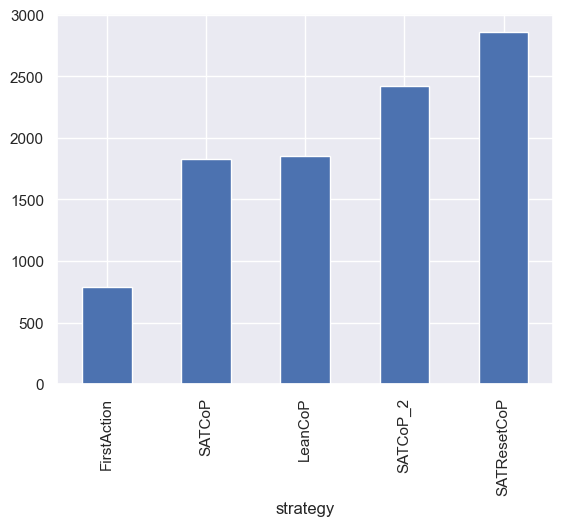

In [19]:
data[data.solved].strategy.value_counts(ascending = True).plot.bar()

In [20]:
data.groupby(['strategy', 'problem_type']).solved.sum().unstack()

problem_type,CNF,FOF
strategy,,
FirstAction,205,587
LeanCoP,701,1155
SATCoP,787,1042
SATCoP_2,1027,1396
SATResetCoP,1227,1634


In [21]:
data[data.strategy == 'SATResetAtStaleAction'].result.value_counts()

Series([], Name: count, dtype: int64)

In [22]:
data[data.strategy == 'SATResetAtTwo'].result.value_counts()

Series([], Name: count, dtype: int64)

In [23]:
merged = pandas.merge(
    data,
    data,
    left_on = 'problem',
    right_on = 'problem',
    suffixes = ('_left', '_right'),
)

In [24]:
pandas.crosstab(merged.strategy_left, merged.strategy_right)

strategy_right,FirstAction,LeanCoP,SATCoP,SATCoP_2,SATResetCoP
strategy_left,,,,,
FirstAction,16442,16442,16442,16442,16442
LeanCoP,16442,16442,16442,16442,16442
SATCoP,16442,16442,16442,16442,16442
SATCoP_2,16442,16442,16442,16442,16442
SATResetCoP,16442,16442,16442,16442,16442


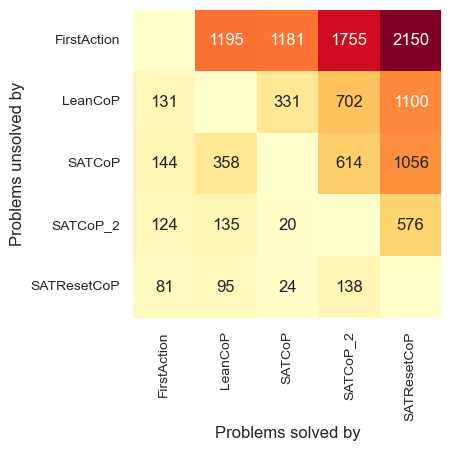

In [25]:
pyplot.rcParams['figure.figsize'] = (4, 4)
values = (
    merged
    [~merged.solved_left & merged.solved_right]
    [['strategy_left', 'strategy_right']]
    .value_counts()
)

# order = values.groupby(level = 'strategy_right').sum().sort_values().index

results = (
    values
    .unstack(level = 'strategy_right', fill_value = 0)
    .rename_axis(index = 'Not solved by this model', columns = 'Solved by this model')
    # .reindex(index = order, columns = order, fill_value = 0)
)

renamer = {
    'SATSolve': 'SATCoP (orig)',
    'SATSolveLiteral': 'SATCoP',
    'SATResetAtStaleAction': 'StaleAction',
	'SATResetAtStaleBacktrack': 'StaleBacktrack',
	'SATResetBandit': 'Bandit',
    'SATResetAtTwoFixedStep': 'ResetAtTwo\'',
    'SATResetAtTwo': 'ResetAtTwo',
}

cols = results.columns[results.columns.str.startswith('SAT') & ~results.columns.str.endswith('Literal')]
cols = results.columns
plot = (
    results.
    loc[cols, cols].
    rename_axis(index = 'Problems unsolved by', columns = 'Problems solved by').
    rename(index = renamer).
    rename(columns = renamer)
)

seaborn.heatmap(
    plot,
    annot = plot.astype(str).where(~numpy.eye(results.index.size, dtype = bool), other = ''),
    fmt = 's',
    cmap = 'YlOrRd',
    square = True,
    cbar = False,
)

pyplot.gca().tick_params(axis = 'both', labelsize = 'small')
pyplot.savefig('Vampire/figures/solved_heatmap.png', bbox_inches = 'tight', dpi = 400)

In [26]:
data[data.solved].time_ms.max()

89964.0

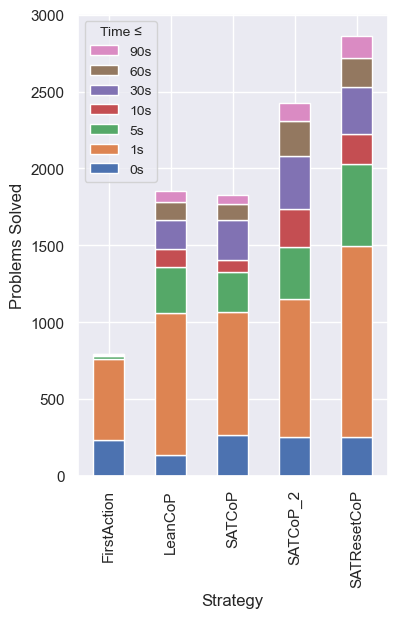

In [27]:
pyplot.rcParams["figure.figsize"] = (4, 6)

times = [0, 1, 5, 10, 30, 60, 90, 120]
solved_time = Series(
    numpy.select(
        [data.solved & (data.time_ms <= 1000 * x) for x in times],
        [x for x in times],
        default = None,
    ),
    index = data.index,
    name = 'solved_time',
)

q = pandas.concat([data, solved_time], axis = 1)[['strategy', 'solved_time']]
b = q.groupby('strategy').value_counts(sort = False).sort_index(level = [0, 1]).unstack()
b.columns = [f'{x}s' for x in b.columns]
b.plot.bar(stacked = True)
pyplot.ylabel('Problems Solved')
pyplot.xlabel('Strategy')
pyplot.legend(loc = 0, fontsize = 'small', reverse = True, title = 'Time ≤', title_fontsize = 'small')

pyplot.savefig('Vampire/figures/strategy_solved_time_plot.png', dpi = 400, bbox_inches = 'tight')

In [28]:
b

,0s,1s,5s,10s,30s,60s,90s
strategy,,,,,,,
FirstAction,235,529,17,5,2,3,1
LeanCoP,136,926,300,117,187,119,71
SATCoP,264,802,260,78,260,103,62
SATCoP_2,256,895,341,243,348,224,116
SATResetCoP,257,1237,532,201,305,187,142


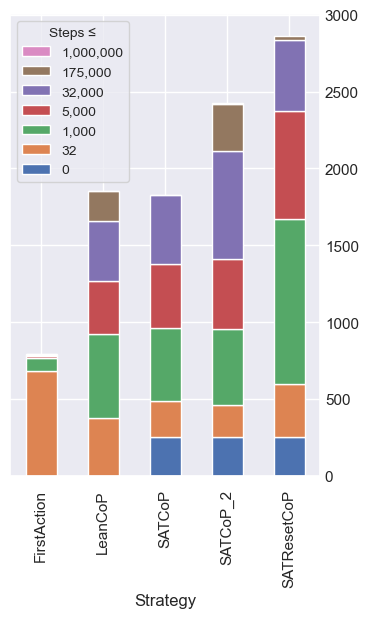

In [29]:
times = [0, 32, 1000, 5000, 32000, 175000, 1000000]
solved_time = Series(
    numpy.select(
        [data.solved & (data.steps <= x) for x in times],
        [x for x in times],
        default = None,
    ),
    index = data.index,
    name = 'solved_time',
)

q = pandas.concat([data, solved_time], axis = 1)[['strategy', 'solved_time']]
b = q.groupby('strategy').value_counts(sort = False).sort_index(level = [0, 1]).unstack()
b.columns = [f'{x:,d}' for x in b.columns]
b.plot.bar(stacked = True)
# pyplot.ylabel('Problems Solved')
pyplot.xlabel('Strategy')
pyplot.legend(loc = 0, fontsize = 'small', reverse = True, title = 'Steps ≤', title_fontsize = 'small')
pyplot.gca().yaxis.tick_right()
pyplot.gca().tick_params(axis = 'y', length = 0)

pyplot.savefig('Vampire/figures/strategy_solved_steps_plot.png', dpi = 400, bbox_inches = 'tight')

In [30]:
b

,0,32,"1,000","5,000","32,000","175,000","1,000,000"
strategy,,,,,,,
FirstAction,NaN,681.0,88.0,11.0,8.0,3.0,1.0
LeanCoP,NaN,377.0,548.0,342.0,393.0,193.0,3.0
SATCoP,252.0,236.0,475.0,419.0,444.0,3.0,NaN
SATCoP_2,253.0,208.0,498.0,454.0,698.0,311.0,1.0
SATResetCoP,253.0,345.0,1075.0,699.0,466.0,23.0,NaN


In [31]:
merged.strategy_right.unique()

array(['FirstAction', 'LeanCoP', 'SATCoP', 'SATCoP_2', 'SATResetCoP'],
      dtype=object)

In [32]:
merged[(merged.strategy_left == 'SATSolveLiteral') & (merged.strategy_right == 'SATResetAtStaleAction') & merged.solved_right & merged.solved_left][['problem', 'steps_left', 'steps_right']]

,problem,steps_left,steps_right


In [33]:
merged.columns

Index(['problem', 'strategy_left', 'status_left', 'result_left', 'solved_left',
       'steps_left', 'time_ms_left', 'problem_spc_tags_left',
       'problem_typed_left', 'problem_declared_status_left',
       'problem_declared_status_kind_left', 'info_left', 'error_left',
       'problem_type_left', 'strategy_right', 'status_right', 'result_right',
       'solved_right', 'steps_right', 'time_ms_right',
       'problem_spc_tags_right', 'problem_typed_right',
       'problem_declared_status_right', 'problem_declared_status_kind_right',
       'info_right', 'error_right', 'problem_type_right'],
      dtype='object')

In [34]:
merged[
    (merged.strategy_left == 'FirstAction') &
    (merged.strategy_right == 'SATSolve') &
    merged.solved_right &
    merged.solved_left &
    (merged.steps_right == 0) &
    (merged.steps_left < 10000)
    ][['problem', 'time_ms_left', 'steps_left', 'time_ms_right', 'steps_right']].sort_values('steps_left', ascending = False)

,problem,time_ms_left,steps_left,time_ms_right,steps_right


In [35]:
data.head()

,problem,strategy,status,result,solved,steps,time_ms,problem_spc_tags,problem_typed,problem_declared_status,problem_declared_status_kind,info,error,problem_type
82844,GRP332-1.p,FirstAction,timeout,NaN,False,105053.0,90001.0,CNF_UNS_RFO_PEQ_NUE,False,Unsatisfiable,unsat,NaN,NaN,CNF
82816,GRP297-1.p,FirstAction,timeout,NaN,False,110591.0,90001.0,CNF_UNS_RFO_PEQ_NUE,False,Unsatisfiable,unsat,NaN,NaN,CNF
82820,GRP302-1.p,FirstAction,timeout,NaN,False,100187.0,90000.0,CNF_UNS_RFO_PEQ_NUE,False,Unsatisfiable,unsat,NaN,NaN,CNF
82824,GRP307-1.p,FirstAction,timeout,NaN,False,105153.0,90001.0,CNF_UNS_RFO_PEQ_NUE,False,Unsatisfiable,unsat,NaN,NaN,CNF
82828,GRP312-1.p,FirstAction,timeout,NaN,False,45745.0,90000.0,CNF_UNS_RFO_PEQ_NUE,False,Unsatisfiable,unsat,NaN,NaN,CNF


In [36]:
pandas.concat(
    [
        data[data.solved & (data.problem_type == 'CNF')].groupby('problem').first().strategy.value_counts().rename('CNF'),
        data[data.solved & (data.problem_type == 'FOF')].groupby('problem').first().strategy.value_counts().rename('FOF'),
    ],
    axis = 1,
)

,CNF,FOF
strategy,,
LeanCoP,502,693
SATResetCoP,213,228
FirstAction,205,587
SATCoP_2,188,189
SATCoP,184,129


In [37]:
nice = merged[(merged.strategy_left == 'SATCoP_2') & (merged.strategy_right == 'SATResetCoP') & ~merged.solved_left & merged.solved_right]

In [38]:
nice.problem.str[:3].value_counts() / data

,ALG,BOO,CAT,COL,COM,CSR,FLD,GEO,GRA,GRP,...,problem_declared_status_kind,problem_spc_tags,problem_type,problem_typed,result,solved,status,steps,strategy,time_ms
82844,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
82816,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
82820,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
82824,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
82828,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
111,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
63,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
119,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Verification

In [39]:
verify = pandas.read_csv('results/SATReset10MinutesFull.csv')

In [40]:
verify

,problem,strategy,status,result,solved,steps,time_ms,problem_spc_tags,problem_typed,problem_declared_status,problem_declared_status_kind,info,error
0,AGT001+1.p,ResetSATCoP,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN
1,AGT001+2.p,ResetSATCoP,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN
2,AGT002+1.p,ResetSATCoP,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN
3,AGT002+2.p,ResetSATCoP,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN
4,AGT003+1.p,ResetSATCoP,solved,Theorem (SAT),True,18417.0,56508.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
15635,TOP049-1.p,ResetSATCoP,max_steps,NaN,False,1000000.0,92607.0,CNF_UNS_RFO_PEQ_UEQ,False,Unsatisfiable,unsat,NaN,NaN
15636,TOP050-1.p,ResetSATCoP,max_steps,NaN,False,1000000.0,182305.0,CNF_UNS_RFO_PEQ_UEQ,False,Unsatisfiable,unsat,NaN,NaN
15637,TOP051-1.p,ResetSATCoP,max_steps,NaN,False,1000000.0,94688.0,CNF_UNS_RFO_PEQ_UEQ,False,Unsatisfiable,unsat,NaN,NaN
15638,TOP052-1.p,ResetSATCoP,timeout,NaN,False,840250.0,600001.0,CNF_UNS_RFO_PEQ_UEQ,False,Unsatisfiable,unsat,NaN,NaN


In [41]:
a = verify[verify.problem_spc_tags.str.contains('FOF')]
b = verify[verify.problem_spc_tags.str.contains('CNF')]

pandas.concat(
    [
        pandas.crosstab(a.problem_declared_status, a.solved),
        pandas.crosstab(b.problem_declared_status, b.solved),
    ],
    keys = ['FOF', 'CNF'],
    axis = 1,
).fillna(0).astype(int)

FOF         CNF      
solved                  False True  False True 
problem_declared_status                        
ContradictoryAxioms       204    39     0     0
CounterSatisfiable        732     0     0     0
Open                        4     0    28     0
Satisfiable               350     0  1094     0
Theorem                  4426  1823     0     0
Unknown                    94     0   745     0
Unsatisfiable             100    72  4496  1433

In [42]:
pandas.crosstab(
    a.problem_declared_status,
    a.solved,
)

solved,False,True
problem_declared_status,,
ContradictoryAxioms,204,39
CounterSatisfiable,732,0
Open,4,0
Satisfiable,350,0
Theorem,4426,1823
Unknown,94,0
Unsatisfiable,100,72
